
# AISE4010 Group 11 ? Stage 2 weekly-reference experiment

Separate experimental copy of the Stage 2 workspace. It retains the RNN, LSTM, GRU, and TCN model families and the existing eight-trial search for each family; the original Stage 2 notebook is unchanged.

## Forecast changes in this copy

- Use the exact same-hour reading 168 hours before each target as a fixed reference.
- Train each model to estimate the residual adjustment from that reference using the past 168 hours and causal daily/weekly trend comparisons.
- Leave the adjustment unconstrained so forecasts can rise above the weekly reference. Keep the existing unweighted MSE objective; report peak-only RMSE alongside overall RMSE instead of increasing peak loss weight without evidence.
- Compare forecasts with both yesterday and last week persistence baselines.

Restart and run this notebook from the top before interpreting results. It saves its checkpoint separately as `models/stage2_weekly_reference_best.pt`.

Input contract: past 168 hourly steps -> next 24 hourly targets. Select candidates with validation-only, measured-hour midnight-origin RMSE. The held-out test data is not used for model selection.


In [1]:
import os

# Convert the raw UCI .txt (';'-separated, '?' = missing) to CSV once
if not os.path.exists('household_power_consumption.csv'):
    with open('household_power_consumption.txt', newline='') as src, open('household_power_consumption.csv', 'w', newline='') as dst:
        for line in src:
            dst.write(line.replace(';', ',').replace('?', ''))

In [2]:
import os, sys
os.environ['PATH'] = os.path.join(sys.prefix, 'Library', 'bin') + os.pathsep + os.environ.get('PATH', '')
import torch
print(sys.executable)
print(torch.backends.cudnn.version())

c:\Users\ahaze\anaconda3\envs\4010-DeepLearning\python.exe
92800


In [3]:

import pandas as pd

df = pd.read_csv('household_power_consumption.csv')
df['Datetime'] = pd.to_datetime(df['Date'] + ' ' + df['Time'], format='%d/%m/%Y %H:%M:%S')
df = df.drop(columns=['Date', 'Time']).set_index('Datetime')
print('Loaded rows:', len(df), '| coverage:', df.index.min(), '->', df.index.max())


Loaded rows: 2075259 | coverage: 2006-12-16 17:24:00 -> 2010-11-26 21:02:00


### GPU check
Confirms which device PyTorch will train on. Every model below is moved to `device`.

In [4]:
import os
import random
import sys
import numpy as np

os.environ['PATH'] = os.path.join(sys.prefix, 'Library', 'bin') + os.pathsep + os.environ.get('PATH', '')
import torch

print('PyTorch', torch.__version__)
print('CUDA available:', torch.cuda.is_available())
print('CUDA version:', torch.version.cuda, '| cuDNN version:', torch.backends.cudnn.version())

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if device.type == 'cuda':
    print('Training on GPU:', torch.cuda.get_device_name(0))
else:
    print('No GPU found, training on CPU')

# A small matmul proves tensors actually land on the chosen device
probe = torch.randn(256, 256, device=device)
print('Test matmul ran on:', (probe @ probe).device)

SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)  # also seeds CUDA

# Deterministic cuDNN kernels so GPU runs repeat exactly with the same seed
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
set_seed()

PyTorch 2.14.1
CUDA available: True
CUDA version: 13.4 | cuDNN version: 92800
Training on GPU: NVIDIA GeForce RTX 4050 Laptop GPU
Test matmul ran on: cuda:0


In [5]:
TARGET = 'Global_active_power'
LOOKBACK, HORIZON = 168, 24
DAY, WEEK = 24, 168


## Resampling and imputation
* **Resample:** hourly mean. Hours with fewer than 30 recorded minutes are set to missing.
* **Short gaps (≤ 3 h):** forward fill, which carries the last observed hour forward.
* **Long gaps (up to about 5 days):** the value from the same hour one week earlier. Any remainder is forward-filled.

Every fill is **causal**: a missing hour is filled only from earlier hours. Interpolation would use the next observed hour, which could be a target hour of the same window. Nothing here is fitted to data either, so imputation cannot leak test statistics into training. The `imputed` mask is kept so we can report how much of each split is filled in.

In [6]:
counts = df[TARGET].resample('h').count()
hourly_raw = df.resample('h').mean()
hourly_raw.loc[counts < 30] = np.nan
imputed = hourly_raw[TARGET].isna()

# Length of each run of missing hours
run_id = (imputed != imputed.shift()).cumsum()
run_len = imputed.groupby(run_id).transform('size')
short_gap = imputed & (run_len <= 3)

hourly = hourly_raw.copy()
hourly.loc[short_gap] = hourly_raw.ffill().loc[short_gap]
for _ in range(2):  # a second pass covers gaps whose previous week was also missing
    hourly = hourly.fillna(hourly.shift(WEEK))
hourly = hourly.ffill().dropna()  # only leading hours with no history can remain; drop them
imputed = imputed.loc[hourly.index]

assert not hourly.isna().any().any()
print(f'Hourly rows: {len(hourly)} | imputed hours: {imputed.sum()} ({imputed.mean():.2%}), '
      f'of which short gaps: {short_gap.sum()}')

Hourly rows: 34589 | imputed hours: 432 (1.25%), of which short gaps: 7


## Shared forecast setup
This compact setup reproduces only the preprocessing and window definitions required by the Stage 2 models. The same chronological 60/20/20 split is used. Scalers and the profile baseline are fitted on training rows only. The Stage 1-selected feature configuration is retained for a fair comparison when the selected Stage 2 model is later integrated into the final notebook.

Each model receives the past 168 hourly feature rows plus calendar and causal trend covariates for each forecast hour. For each of the 24 targets, its fixed reference is the exact same-hour observation 168 hours earlier. The model learns an additive correction to that reference. Trend covariates use only the preceding 168 hours, and future power measurements are never provided as inputs.


In [7]:
features = hourly.copy()
idx = features.index
dow = idx.day_of_week.to_numpy()
year_phase = 2 * np.pi * ((idx.day_of_year.to_numpy() - 1) + idx.hour.to_numpy() / 24) / 365.2425
features['hour_sin'] = np.sin(2 * np.pi * idx.hour / 24)
features['hour_cos'] = np.cos(2 * np.pi * idx.hour / 24)
features['dow_sin'] = np.sin(2 * np.pi * dow / 7)
features['dow_cos'] = np.cos(2 * np.pi * dow / 7)
features['is_weekend'] = (dow >= 5).astype(float)
for harmonic in (1, 2):
    features[f'year_sin_{harmonic}'] = np.sin(harmonic * year_phase)
    features[f'year_cos_{harmonic}'] = np.cos(harmonic * year_phase)

# Calendar values for forecast timestamps are known at prediction time.
FUTURE_CALENDAR_FEATURES = [
    'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'is_weekend',
    'year_sin_1', 'year_cos_1', 'year_sin_2', 'year_cos_2',
]

past_gap = hourly[TARGET]
causal_mean = past_gap.shift(1).expanding(min_periods=1).mean().fillna(past_gap.iloc[0])
features['GAP_lag_1d'] = past_gap.shift(DAY).fillna(causal_mean)
features['GAP_lag_1w'] = past_gap.shift(WEEK).fillna(causal_mean)
FUTURE_TREND_FEATURES = [
    'GAP_lag_1d_standardized', 'GAP_lag_1d_vs_1w', 'GAP_lag_1d_vs_2d',
    'GAP_recent_day_vs_week_mean', 'GAP_recent_day_change', 'GAP_recent_week_change',
]
FUTURE_KNOWN_FEATURES = FUTURE_CALENDAR_FEATURES + FUTURE_TREND_FEATURES
FUTURE_REFERENCE_FEATURE = 'GAP_lag_1w_reference'
FUTURE_MODEL_FEATURES = FUTURE_KNOWN_FEATURES + [FUTURE_REFERENCE_FEATURE]
annual_index = idx - pd.DateOffset(years=1)
annual_lag = past_gap.reindex(annual_index).to_numpy()
features['GAP_lag_1y_available'] = np.isfinite(annual_lag).astype(float)
features['GAP_lag_1y'] = np.where(np.isfinite(annual_lag), annual_lag, causal_mean.to_numpy())
for days in (7, 28):
    trailing = past_gap.shift(1).rolling(days * 24, min_periods=24).mean()
    features[f'GAP_mean_{days}d'] = trailing.fillna(causal_mean)

n = len(features)
train_end, val_end = int(n * 0.6), int(n * 0.8)
splits = {'train': (0, train_end), 'val': (train_end, val_end), 'test': (val_end, n)}
pd.DataFrame([{'split': s, 'start': features.index[a], 'end': features.index[b - 1], 'hours': b - a,
               'imputed %': round(imputed.iloc[a:b].mean() * 100, 2)}
              for s, (a, b) in splits.items()]).set_index('split')


,start,end,hours,imputed %
split,,,,
train,2006-12-16 17:00:00,2009-04-29 09:00:00,20753,0.33
val,2009-04-29 10:00:00,2010-02-11 15:00:00,6918,1.76
test,2010-02-11 16:00:00,2010-11-26 21:00:00,6918,3.50



### Causal seasonal baseline
The Stage 1-selected `profile` baseline (hour-of-week mean, fitted on training rows) is retained to match the established Stage 1 input/target representation. Calendar features and rolling/annual features are generated causally; no centered or future-looking features are used.


In [8]:

gap = hourly[TARGET].to_numpy()
how = (features.index.day_of_week * 24 + features.index.hour).to_numpy()
profile = pd.Series(gap[:train_end]).groupby(how[:train_end]).mean()
weekly_profile = profile.reindex(how).to_numpy()
train_residual = gap[:train_end] - weekly_profile[:train_end]
month_effect = pd.Series(train_residual).groupby(features.index.month[:train_end]).mean()
annual_adjustment = pd.Series(features.index.month).map(month_effect).fillna(0.0).to_numpy()
annual_profile = weekly_profile + annual_adjustment
seasonal_base = {
    'none': np.zeros(n),
    'week': np.r_[np.full(WEEK, np.nan), gap[:-WEEK]],
    'profile': weekly_profile,
    'profile_year': annual_profile,
}


In [9]:
from sklearn.preprocessing import StandardScaler

def to_kw(y, split):
    """Undo target scaling and add the training-fitted seasonal baseline back in kW."""
    return y * x_scaler.scale_[TARGET_IDX] + x_scaler.mean_[TARGET_IDX] + base[split]

def make_windows(start, end):
    """Windows whose 24-hour target lies in [start, end); lookback may use earlier rows."""
    t = np.arange(max(start, LOOKBACK + WEEK), end - HORIZON + 1)
    X = np.stack([X_all[i - LOOKBACK:i] for i in t])
    y = np.stack([X_all[i:i + HORIZON, TARGET_IDX] for i in t])
    return X, y, t

def prepare(variant, drop):
    """Build history windows, causal trends, and exact weekly-reference residual targets."""
    global FEATURES, TARGET_IDX, x_scaler, X_all, data, base, measured, daily_origin, Y_kw
    global X_train, y_train, X_val, y_val, future_calendar, model_targets
    frame = features.drop(columns=drop)
    target_col = TARGET
    if variant != 'none':
        frame['GAP_resid'] = gap - seasonal_base[variant]
        target_col = 'GAP_resid'
    FEATURES = list(frame.columns)
    TARGET_IDX = FEATURES.index(target_col)
    x_scaler = StandardScaler().fit(frame.iloc[:train_end])
    X_all = x_scaler.transform(frame).astype(np.float32)

    data = {s: make_windows(a, b) for s, (a, b) in splits.items()}
    hours = {s: t[:, None] + np.arange(HORIZON) for s, (_, _, t) in data.items()}
    base = {s: seasonal_base[variant][h] for s, h in hours.items()}
    future_calendar = {}
    for split, windows in data.items():
        future_rows = []
        for window_index, start in enumerate(windows[2]):
            target_hours = start + np.arange(HORIZON)
            day_lag = gap[target_hours - DAY]
            week_reference = gap[target_hours - WEEK]
            two_day_lag = gap[target_hours - 2 * DAY]
            recent_history = gap[start - LOOKBACK:start]
            target_base = base[split][window_index]
            target_scale = x_scaler.scale_[TARGET_IDX]
            target_mean = x_scaler.mean_[TARGET_IDX]
            trend_features = np.column_stack([
                (day_lag - target_base - target_mean) / target_scale,
                (day_lag - week_reference) / target_scale,
                (day_lag - two_day_lag) / target_scale,
                np.full(HORIZON, (recent_history[-DAY:].mean() - recent_history.mean()) / target_scale),
                np.full(HORIZON, (recent_history[-DAY:].mean() - recent_history[-2 * DAY:-DAY].mean()) / target_scale),
                np.full(HORIZON, (recent_history[-DAY:].mean() - recent_history[:DAY].mean()) / target_scale),
            ])
            reference_feature = (
                (week_reference - target_base - target_mean) / target_scale
            )[:, None]
            calendar_features = features.iloc[start:start + HORIZON][
                FUTURE_CALENDAR_FEATURES
            ].to_numpy(dtype=np.float32)
            future_rows.append(np.concatenate(
                [calendar_features, trend_features, reference_feature], axis=1
            ).astype(np.float32))
        future_calendar[split] = np.stack(future_rows)

    model_targets = {
        split: y - future_calendar[split][..., -1]
        for split, (_, y, _) in data.items()
    }
    measured = {s: ~imputed.to_numpy()[h] for s, h in hours.items()}
    daily_origin = {s: features.index[t].hour.to_numpy() == 0 for s, (_, _, t) in data.items()}
    Y_kw = {s: to_kw(y, s) for s, (_, y, _) in data.items()}

    X_train, y_train, t_train = data['train']
    X_val, y_val, t_val = data['val']
    assert X_train.shape[1:] == (LOOKBACK, len(FEATURES)) and y_train.shape[1] == HORIZON
    assert future_calendar['train'].shape[1:] == (HORIZON, len(FUTURE_MODEL_FEATURES))
    assert t_train[-1] + HORIZON <= train_end and t_val[-1] + HORIZON <= val_end
    assert all(np.isfinite(X).all() for X, _, _ in data.values())
    assert all(np.isfinite(F).all() for F in future_calendar.values())
    for split, target_hours in hours.items():
        assert np.allclose(Y_kw[split], gap[target_hours], atol=1e-3)
        reference_kw = (
            future_calendar[split][..., -1] * x_scaler.scale_[TARGET_IDX]
            + x_scaler.mean_[TARGET_IDX] + base[split]
        )
        assert np.allclose(reference_kw, gap[target_hours - WEEK], atol=1e-3)

best_variant = 'profile'
best_drop = ['Global_intensity', 'Voltage', 'Global_reactive_power']
prepare(best_variant, best_drop)
print('Training windows:', X_train.shape, '| 24-hour targets:', y_train.shape[1])
print('Future calendar, trend, and exact weekly reference inputs:', future_calendar['train'].shape)


Training windows: (20394, 168, 20) | 24-hour targets: 24
Future calendar, trend, and exact weekly reference inputs: (20394, 24, 16)


In [10]:
import copy
import time
from torch import nn

BATCH = 64
MAX_EPOCHS, PATIENCE = 100, 10

def evaluate(y_true, y_pred, mask=None):
    error = y_pred - y_true
    if mask is not None:
        error = error[mask]
    return {'MAE': np.abs(error).mean(), 'RMSE': np.sqrt(np.mean(error ** 2))}

def count_params(model):
    return sum(parameter.numel() for parameter in model.parameters())

def predict(model, X, future):
    model.eval()
    with torch.no_grad():
        batches = [
            model(x_batch.to(device), future_batch.to(device)).cpu()
            for x_batch, future_batch in zip(
                torch.from_numpy(X).split(1024), torch.from_numpy(future).split(1024)
            )
        ]
    adjustment = torch.cat(batches)
    weekly_reference = torch.from_numpy(future[..., -1])
    return (adjustment + weekly_reference).numpy()

def fit(build, train, val, lr=3e-4, batch_size=BATCH, weight_decay=1e-2,
        max_epochs=MAX_EPOCHS, patience=PATIENCE):
    """Train with validation-MSE early stopping and return the best checkpoint and loss history."""
    set_seed()
    model = build().to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    loss_fn = nn.MSELoss()
    X_train_device, y_train_device, future_train_device = (
        torch.from_numpy(array).to(device) for array in train
    )
    X_val_device, y_val_device, future_val_device = (
        torch.from_numpy(array).to(device) for array in val
    )
    history = {'train': [], 'val': []}
    best_loss, best_state, wait = float('inf'), copy.deepcopy(model.state_dict()), 0
    start = time.perf_counter()
    for _ in range(max_epochs):
        model.train()
        total_loss = 0.0
        for indices in torch.randperm(len(X_train_device), device=device).split(batch_size):
            optimizer.zero_grad()
            prediction = model(X_train_device[indices], future_train_device[indices])
            loss = loss_fn(prediction, y_train_device[indices])
            loss.backward()
            optimizer.step()
            total_loss += loss.detach() * len(indices)
        model.eval()
        with torch.no_grad():
            validation_loss = sum(
                loss_fn(model(x_batch, f_batch), y_batch).item() * len(x_batch)
                for x_batch, y_batch, f_batch in zip(
                    X_val_device.split(1024), y_val_device.split(1024), future_val_device.split(1024)
                )
            ) / len(X_val_device)
        history['train'].append(total_loss.item() / len(X_train_device))
        history['val'].append(validation_loss)
        if validation_loss < best_loss:
            best_loss, wait = validation_loss, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            wait += 1
            if wait >= patience:
                break
    model.load_state_dict(best_state)
    return model, history, time.perf_counter() - start


## Stage 2 ? recurrent models and TCN
Compare a vanilla RNN, LSTM, GRU, and TCN using the same Stage 1-selected features, chronological split, training procedure, and equal eight-trial validation search per family. Models receive the past 168 hours plus future calendar/trend covariates and the exact weekly reference for each target; they predict an additive correction to that reference. No future power observations are inputs.


In [11]:
# Confirm the unchanged forecasting contract before fitting additional models.
assert X_train.shape[1] == LOOKBACK == 168
assert y_train.shape[1] == HORIZON == 24
assert future_calendar['train'].shape[1] == HORIZON
assert future_calendar['train'].shape[2] == len(FUTURE_MODEL_FEATURES)

LEAD_EMBEDDING_DIM = 8

class RecurrentForecaster(nn.Module):
    def __init__(self, cell='GRU', hidden=64, layers=3, dropout=0.1):
        super().__init__()
        recurrent = {'RNN': nn.RNN, 'LSTM': nn.LSTM, 'GRU': nn.GRU}[cell]
        self.encoder = recurrent(
            input_size=len(FEATURES), hidden_size=hidden, num_layers=layers,
            batch_first=True, dropout=dropout if layers > 1 else 0.0,
        )
        self.lead_embedding = nn.Embedding(HORIZON, LEAD_EMBEDDING_DIM)
        self.head = nn.Sequential(
            nn.Linear(hidden + len(FUTURE_MODEL_FEATURES) + LEAD_EMBEDDING_DIM, hidden),
            nn.ReLU(),
            nn.Linear(hidden, 1),
        )

    def forward(self, x, future_calendar):
        sequence, _ = self.encoder(x)
        context = sequence[:, -1:, :].expand(-1, HORIZON, -1)
        lead_steps = torch.arange(HORIZON, device=x.device)
        lead = self.lead_embedding(lead_steps).unsqueeze(0).expand(x.shape[0], -1, -1)
        known_features = future_calendar
        decoder_input = torch.cat([context, known_features, lead], dim=-1)
        return self.head(decoder_input).squeeze(-1)

class CausalConv1d(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size, dilation):
        super().__init__()
        self.left_padding = (kernel_size - 1) * dilation
        self.conv = nn.Conv1d(
            in_channels, out_channels, kernel_size,
            padding=self.left_padding, dilation=dilation,
        )

    def forward(self, x):
        output = self.conv(x)
        if self.left_padding:
            output = output[..., :-self.left_padding]
        return output

class TemporalBlock(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size, dilation, dropout):
        super().__init__()
        self.conv1 = CausalConv1d(in_channels, out_channels, kernel_size, dilation)
        self.conv2 = CausalConv1d(out_channels, out_channels, kernel_size, dilation)
        self.dropout = nn.Dropout(dropout)
        self.activation = nn.ReLU()
        self.skip = nn.Conv1d(in_channels, out_channels, 1) if in_channels != out_channels else nn.Identity()

    def forward(self, x):
        residual = self.skip(x)
        output = self.dropout(self.activation(self.conv1(x)))
        output = self.dropout(self.activation(self.conv2(output)))
        return self.activation(output + residual)

class TCNForecaster(nn.Module):
    def __init__(self, hidden=32, layers=8, dropout=0.1, kernel_size=3):
        super().__init__()
        blocks = []
        in_channels = len(FEATURES)
        for level in range(layers):
            blocks.append(TemporalBlock(
                in_channels, hidden, kernel_size, dilation=2 ** min(level, 5), dropout=dropout,
            ))
            in_channels = hidden
        self.encoder = nn.Sequential(*blocks)
        self.lead_embedding = nn.Embedding(HORIZON, LEAD_EMBEDDING_DIM)
        self.head = nn.Sequential(
            nn.Linear(hidden + len(FUTURE_MODEL_FEATURES) + LEAD_EMBEDDING_DIM, hidden),
            nn.ReLU(),
            nn.Linear(hidden, 1),
        )

    def forward(self, x, future_calendar):
        encoded = self.encoder(x.transpose(1, 2))
        context = encoded[:, :, -1].unsqueeze(1).expand(-1, HORIZON, -1)
        lead_steps = torch.arange(HORIZON, device=x.device)
        lead = self.lead_embedding(lead_steps).unsqueeze(0).expand(x.shape[0], -1, -1)
        known_features = future_calendar
        decoder_input = torch.cat([context, known_features, lead], dim=-1)
        return self.head(decoder_input).squeeze(-1)

stage2_builders = {
    'RNN': lambda **config: RecurrentForecaster(cell='RNN', **config),
    'LSTM': lambda **config: RecurrentForecaster(cell='LSTM', **config),
    'GRU': lambda **config: RecurrentForecaster(cell='GRU', **config),
    'TCN': lambda **config: TCNForecaster(**config),
}


### Equal-budget Stage 2 comparison
Each model consumes `(batch, 168, features)` plus calendar and causal trend covariates for the 24 target hours. The last future covariate is the exact same-hour reading from 168 hours before each target, standardized in the target residual coordinate. Models train to predict the correction from that weekly reference; inference adds the correction back to the reference without clipping. The encoder sees all 168 history hours and a lead embedding distinguishes each forecast hour. RNN, LSTM, GRU, and TCN keep the existing eight-trial search each. Model selection remains based on measured-hour midnight-origin validation RMSE; peak-only RMSE is reported separately from overall RMSE.

RNN trial 1/8: daily-start RMSE=0.5994 kW
RNN trial 2/8: daily-start RMSE=0.6036 kW
RNN trial 3/8: daily-start RMSE=0.6041 kW
RNN trial 4/8: daily-start RMSE=0.6043 kW
RNN trial 5/8: daily-start RMSE=0.5969 kW
RNN trial 6/8: daily-start RMSE=0.5992 kW
RNN trial 7/8: daily-start RMSE=0.5964 kW
RNN trial 8/8: daily-start RMSE=0.6008 kW
LSTM trial 1/8: daily-start RMSE=0.6089 kW
LSTM trial 2/8: daily-start RMSE=0.6120 kW
LSTM trial 3/8: daily-start RMSE=0.6106 kW
LSTM trial 4/8: daily-start RMSE=0.6121 kW
LSTM trial 5/8: daily-start RMSE=0.6096 kW
LSTM trial 6/8: daily-start RMSE=0.6124 kW
LSTM trial 7/8: daily-start RMSE=0.6132 kW
LSTM trial 8/8: daily-start RMSE=0.6142 kW
GRU trial 1/8: daily-start RMSE=0.6082 kW
GRU trial 2/8: daily-start RMSE=0.6090 kW
GRU trial 3/8: daily-start RMSE=0.6065 kW
GRU trial 4/8: daily-start RMSE=0.6090 kW
GRU trial 5/8: daily-start RMSE=0.6073 kW
GRU trial 6/8: daily-start RMSE=0.6129 kW
GRU trial 7/8: daily-start RMSE=0.6049 kW
GRU trial 8/8: daily-start

,hidden,layers,dropout,lr,val MAE (daily starts),val RMSE (daily starts),val MAE (all hours),val RMSE (all hours),val peak RMSE (daily starts),val peak observations (daily starts),parameters,training time (s),epochs,kernel_size
family,,,,,,,,,,,,,,
RNN,32,3,0.2,0.0003,0.4257,0.5964,0.4272,0.5976,1.3363,489,8001,27.0863,23,NaN
GRU,32,3,0.2,0.0003,0.4371,0.6049,0.4392,0.6054,1.4083,489,19905,23.7965,14,NaN
TCN,64,10,0.2,0.0010,0.4399,0.6052,0.4413,0.6050,1.3792,489,245889,49.1621,11,3.0
LSTM,32,3,0.0,0.0010,0.4513,0.6089,0.4511,0.6084,1.3515,489,25857,14.7849,11,NaN


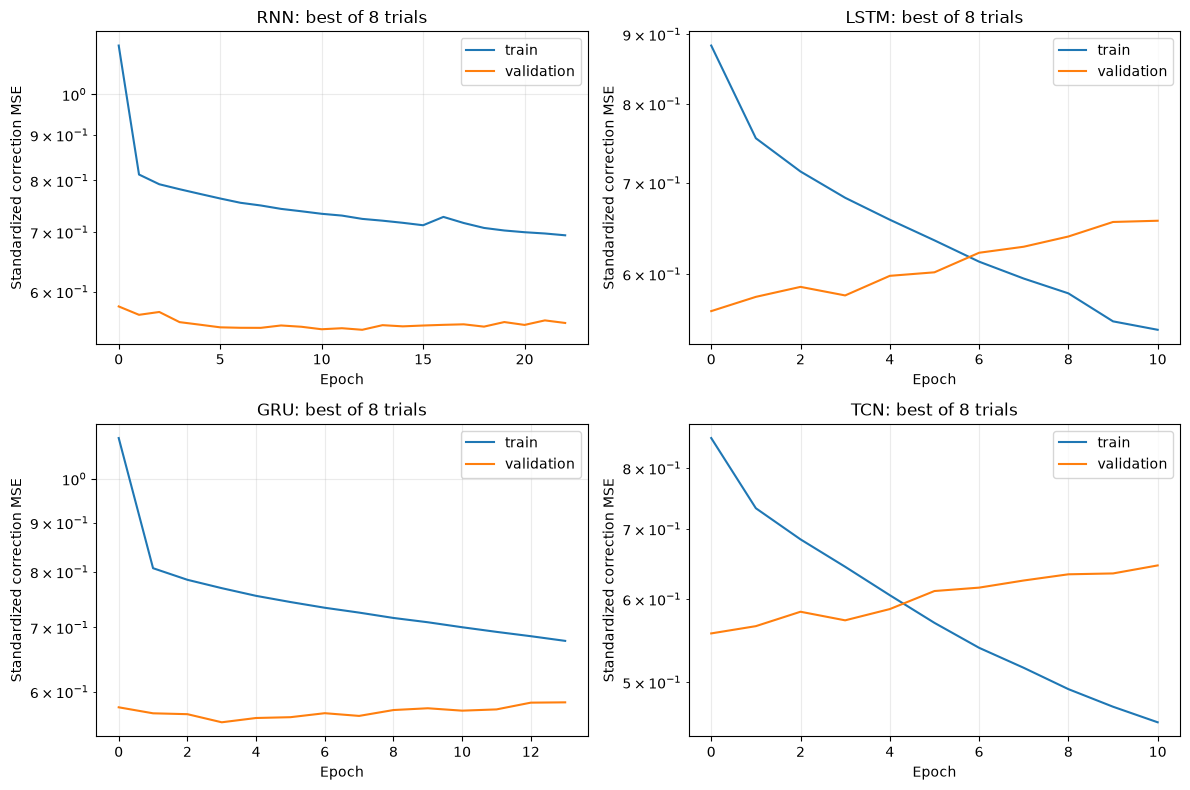

In [12]:
import os
import matplotlib.pyplot as plt

# Eight configurations are evaluated per family with deeper recurrent stacks and TCN blocks (32 fits total).
recurrent_trials = [
    {'hidden': 32, 'layers': 3, 'dropout': 0.0, 'lr': 1e-3},
    {'hidden': 32, 'layers': 4, 'dropout': 0.1, 'lr': 3e-4},
    {'hidden': 64, 'layers': 3, 'dropout': 0.2, 'lr': 1e-4},
    {'hidden': 64, 'layers': 4, 'dropout': 0.0, 'lr': 3e-4},
    {'hidden': 128, 'layers': 3, 'dropout': 0.1, 'lr': 1e-4},
    {'hidden': 128, 'layers': 4, 'dropout': 0.2, 'lr': 1e-3},
    {'hidden': 32, 'layers': 3, 'dropout': 0.2, 'lr': 3e-4},
    {'hidden': 64, 'layers': 4, 'dropout': 0.1, 'lr': 1e-3},
]
tcn_trials = [
    {'hidden': 16, 'layers': 8, 'dropout': 0.0, 'kernel_size': 3, 'lr': 1e-3},
    {'hidden': 16, 'layers': 10, 'dropout': 0.1, 'kernel_size': 3, 'lr': 3e-4},
    {'hidden': 32, 'layers': 8, 'dropout': 0.2, 'kernel_size': 3, 'lr': 1e-4},
    {'hidden': 32, 'layers': 10, 'dropout': 0.0, 'kernel_size': 3, 'lr': 3e-4},
    {'hidden': 64, 'layers': 8, 'dropout': 0.1, 'kernel_size': 3, 'lr': 1e-4},
    {'hidden': 64, 'layers': 10, 'dropout': 0.2, 'kernel_size': 3, 'lr': 1e-3},
    {'hidden': 16, 'layers': 8, 'dropout': 0.2, 'kernel_size': 3, 'lr': 3e-4},
    {'hidden': 32, 'layers': 10, 'dropout': 0.1, 'kernel_size': 3, 'lr': 1e-3},
]

train_data = (X_train, model_targets['train'], future_calendar['train'])
val_data = (X_val, model_targets['val'], future_calendar['val'])
stage2_daily_mask = measured['val'] & daily_origin['val'][:, None]
stage2_all_mask = measured['val']
measured_train_power = gap[:train_end][~imputed.to_numpy()[:train_end]]
if len(measured_train_power) == 0:
    raise ValueError('Cannot calculate peak threshold without measured training targets')
PEAK_THRESHOLD_KW = float(np.quantile(measured_train_power, 0.90))
stage2_daily_peak_mask = stage2_daily_mask & (Y_kw['val'] >= PEAK_THRESHOLD_KW)
stage2_best_by_family, stage2_trials = {}, []

for family in stage2_builders:
    configs = tcn_trials if family == 'TCN' else recurrent_trials
    family_best = {'val RMSE (daily starts)': float('inf')}
    for trial_index, config in enumerate(configs, start=1):
        model_config = {key: value for key, value in config.items() if key != 'lr'}
        model, history, secs = fit(
            lambda family=family, model_config=model_config: stage2_builders[family](**model_config),
            train_data, val_data,
            lr=config['lr'], batch_size=BATCH, weight_decay=1e-2,
        )
        prediction_kw = to_kw(
            predict(model, X_val, future_calendar['val']), 'val'
        )
        daily_metrics = evaluate(Y_kw['val'], prediction_kw, stage2_daily_mask)
        all_metrics = evaluate(Y_kw['val'], prediction_kw, stage2_all_mask)
        peak_errors = prediction_kw - Y_kw['val']
        peak_rmse = (
            float(np.sqrt(np.mean(peak_errors[stage2_daily_peak_mask] ** 2)))
            if stage2_daily_peak_mask.any() else np.nan
        )
        row = {
            'family': family, **config,
            'val MAE (daily starts)': daily_metrics['MAE'],
            'val RMSE (daily starts)': daily_metrics['RMSE'],
            'val MAE (all hours)': all_metrics['MAE'],
            'val RMSE (all hours)': all_metrics['RMSE'],
            'val peak RMSE (daily starts)': peak_rmse,
            'val peak observations (daily starts)': int(stage2_daily_peak_mask.sum()),
            'parameters': count_params(model), 'training time (s)': secs,
            'epochs': len(history['val']),
        }
        stage2_trials.append(row)
        if daily_metrics['RMSE'] < family_best['val RMSE (daily starts)']:
            family_best = {
                **row, 'model': model, 'history': history,
                'config': model_config,
                'train_config': {
                    'lr': config['lr'], 'batch_size': BATCH, 'weight_decay': 1e-2,
                    'forecast_reference': 'same_hour_168_hours_before_target',
                    'peak_threshold_kw_diagnostic': PEAK_THRESHOLD_KW,
                    'peak_loss_weighting': False,
                },
            }
        print(f'{family} trial {trial_index}/8: daily-start RMSE={daily_metrics["RMSE"]:.4f} kW')
    stage2_best_by_family[family] = family_best

stage2_hpo_results = pd.DataFrame(stage2_trials).sort_values(
    ['family', 'val RMSE (daily starts)']
)
stage2_family_results = pd.DataFrame([
    {key: value for key, value in best.items() if key not in ('model', 'history', 'config', 'train_config')}
    for best in stage2_best_by_family.values()
]).set_index('family').sort_values('val RMSE (daily starts)')
print('Best configuration per family (all tuning/selection uses validation only):')
display(stage2_family_results.round(4))

# Best family learning curves help distinguish optimization/underfit from overfit.
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=False)
for ax, (family, best) in zip(axes.flat, stage2_best_by_family.items()):
    ax.plot(best['history']['train'], label='train')
    ax.plot(best['history']['val'], label='validation')
    ax.set(title=f'{family}: best of 8 trials', xlabel='Epoch', ylabel='Standardized correction MSE')
    ax.set_yscale('log')
    ax.grid(True, alpha=0.25)
    ax.legend()
plt.tight_layout()
plt.show()


### Validation-only tuning and diagnostics
Each of the RNN, LSTM, GRU, and TCN families retains eight trials. Each model trains on an additive correction to the same-hour-last-week reference; the target and reference use the same train-fitted scaling. Daily and weekly trend inputs use only history available at the forecast origin. Predictions are not clipped and the original unweighted MSE objective is unchanged. Family selection uses unweighted measured-hour daily-start RMSE. The 90th-percentile training-demand threshold is used only to report peak-only validation RMSE, alongside overall RMSE; it does not change the loss. Lead-hour errors compare the model with both day- and week-naive baselines. The held-out test split is not used here.

Selected RNN using validation daily-start RMSE: 0.5964 kW
Peak-only RMSE uses measured validation targets >= training q90 (2.484 kW); it is diagnostic only.
Validation lead-hour model, day-naive, week-naive, and peak errors (midnight-origin forecasts):


,RMSE (kW),MAE (kW),Bias (kW),Day-naive RMSE (kW),Week-naive RMSE (kW),Peak RMSE (kW),measured peak observations,measured observations
forecast hour,,,,,,,,
1,0.4045,0.3062,0.0619,0.6003,0.5175,1.4014,1,283
2,0.3692,0.2514,-0.0009,0.4967,0.4735,NaN,0,282
3,0.3069,0.2027,-0.0313,0.3828,0.3798,NaN,0,282
4,0.2615,0.1706,-0.0250,0.3552,0.3257,NaN,0,282
5,0.2436,0.1646,-0.0180,0.2985,0.3097,NaN,0,282
6,0.2840,0.1978,-0.0158,0.3377,0.3367,NaN,0,281
7,0.3576,0.2848,0.0225,0.4635,0.4753,NaN,0,281
8,0.6392,0.5170,-0.1007,1.0105,0.7541,1.0424,40,281
9,0.5004,0.3752,-0.0182,0.7242,0.6758,1.1429,15,282


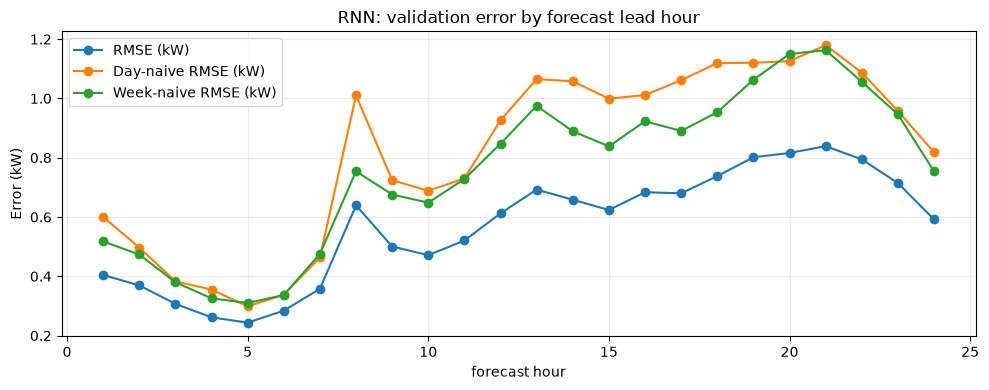

Overall validation RMSE (daily starts): 0.5964 kW
Overall validation RMSE (all origins): 0.5976 kW
Peak-only validation RMSE (daily starts): 1.3363 kW; observations: 489


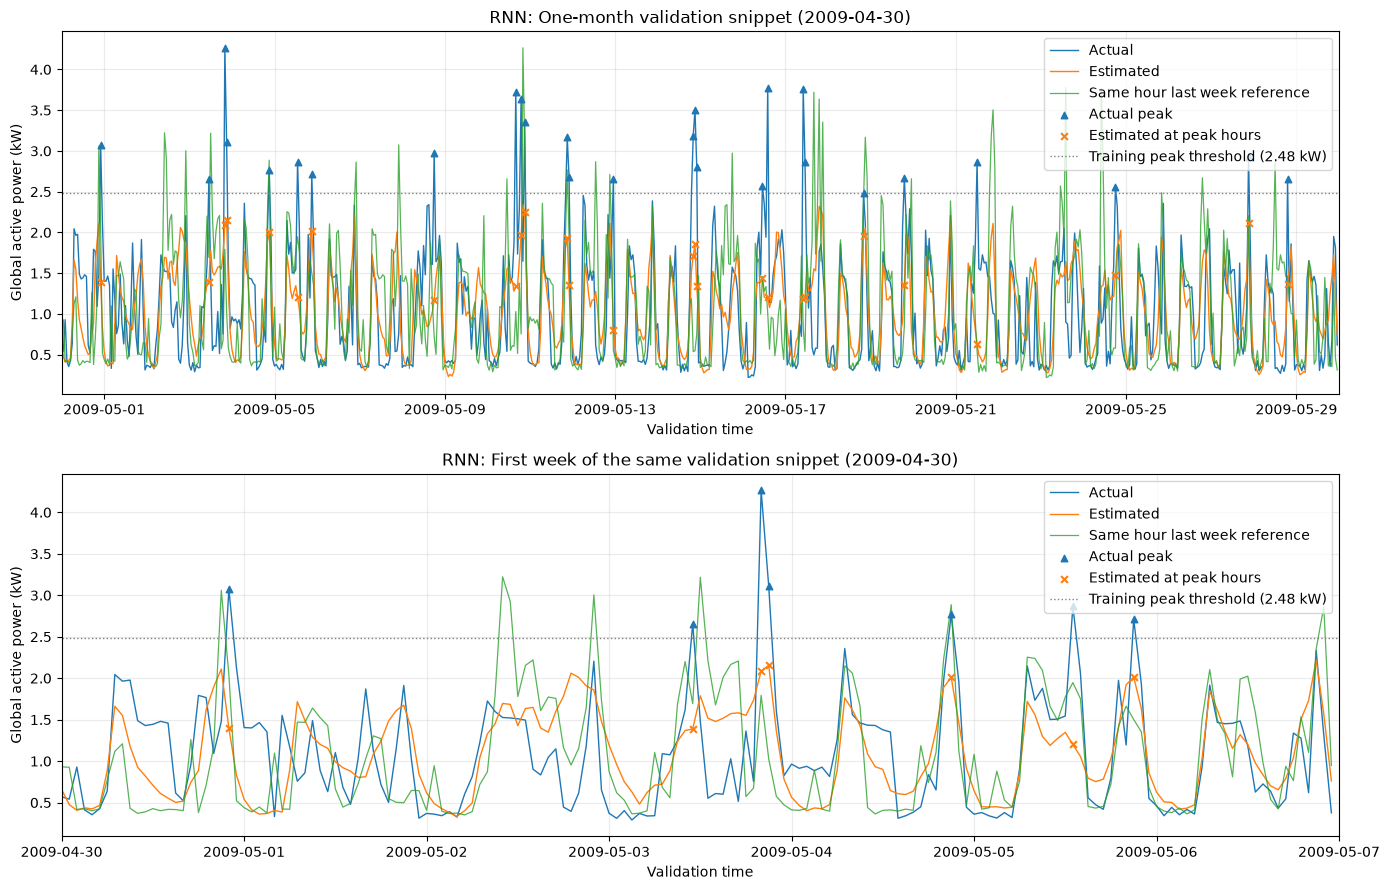

Saved and reloaded separate weekly-reference checkpoint; smoke forecast shape: (8, 24)


In [15]:
# Lock the best Stage 2 family using daily-start validation RMSE, then inspect lead-hour errors.
stage2_family = stage2_family_results.index[0]
stage2_best = stage2_best_by_family[stage2_family]
stage2_tuned = stage2_best['model']
stage2_tuned_name = f'{stage2_family} (Stage 2 weekly-reference experiment)'
stage2_tuned_inference = None

def inference_ms_per_1000_windows(model, X, future, repeats=3):
    sample, future_sample = X[:min(1024, len(X))], future[:min(1024, len(future))]
    predict(model, sample, future_sample)
    if device.type == 'cuda':
        torch.cuda.synchronize(device)
    start = time.perf_counter()
    for _ in range(repeats):
        predict(model, sample, future_sample)
    if device.type == 'cuda':
        torch.cuda.synchronize(device)
    elapsed = time.perf_counter() - start
    return elapsed * 1_000_000 / (repeats * len(sample))

stage2_tuned_inference = inference_ms_per_1000_windows(
    stage2_tuned, X_val, future_calendar['val']
)

prediction_kw = to_kw(
    predict(stage2_tuned, X_val, future_calendar['val']), 'val'
)
daily_error = prediction_kw - Y_kw['val']
target_hours = data['val'][2][:, None] + np.arange(HORIZON)
day_naive_kw = gap[target_hours - DAY]
week_naive_kw = gap[target_hours - WEEK]
day_naive_error = day_naive_kw - Y_kw['val']
week_naive_error = week_naive_kw - Y_kw['val']
daily_rows = daily_origin['val']
lead_rows = []
for lead_hour in range(HORIZON):
    valid = measured['val'][daily_rows, lead_hour]
    errors = daily_error[daily_rows, lead_hour][valid]
    day_errors = day_naive_error[daily_rows, lead_hour][valid]
    week_errors = week_naive_error[daily_rows, lead_hour][valid]
    peak_valid = valid & (Y_kw['val'][daily_rows, lead_hour] >= PEAK_THRESHOLD_KW)
    peak_errors = daily_error[daily_rows, lead_hour][peak_valid]
    lead_rows.append({
        'forecast hour': lead_hour + 1,
        'RMSE (kW)': np.sqrt(np.mean(errors ** 2)),
        'MAE (kW)': np.mean(np.abs(errors)),
        'Bias (kW)': np.mean(errors),
        'Day-naive RMSE (kW)': np.sqrt(np.mean(day_errors ** 2)),
        'Week-naive RMSE (kW)': np.sqrt(np.mean(week_errors ** 2)),
        'Peak RMSE (kW)': np.sqrt(np.mean(peak_errors ** 2)) if len(peak_errors) else np.nan,
        'measured peak observations': len(peak_errors),
        'measured observations': len(errors),
    })
stage2_horizon_errors = pd.DataFrame(lead_rows).set_index('forecast hour')
print(f'Selected {stage2_family} using validation daily-start RMSE: {stage2_best["val RMSE (daily starts)"]:.4f} kW')
print(f'Peak-only RMSE uses measured validation targets >= training q90 ({PEAK_THRESHOLD_KW:.3f} kW); it is diagnostic only.')
print('Validation lead-hour model, day-naive, week-naive, and peak errors (midnight-origin forecasts):')
display(stage2_horizon_errors.round(4))
stage2_horizon_errors[['RMSE (kW)', 'Day-naive RMSE (kW)', 'Week-naive RMSE (kW)']].plot(
    figsize=(10, 4), marker='o', title=f'{stage2_family}: validation error by forecast lead hour'
)
plt.ylabel('Error (kW)')
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

stage2_daily_metrics = evaluate(Y_kw['val'], prediction_kw, measured['val'] & daily_rows[:, None])
stage2_all_metrics = evaluate(Y_kw['val'], prediction_kw, measured['val'])
stage2_peak_mask = measured['val'] & daily_rows[:, None] & (Y_kw['val'] >= PEAK_THRESHOLD_KW)
stage2_peak_rmse = (
    np.sqrt(np.mean(daily_error[stage2_peak_mask] ** 2))
    if stage2_peak_mask.any() else np.nan
)
print('Overall validation RMSE (daily starts):', round(stage2_daily_metrics['RMSE'], 4), 'kW')
print('Overall validation RMSE (all origins):', round(stage2_all_metrics['RMSE'], 4), 'kW')
print('Peak-only validation RMSE (daily starts):', round(float(stage2_peak_rmse), 4), 'kW; observations:', int(stage2_peak_mask.sum()))

daily_val_predictions = prediction_kw[daily_rows]
daily_val_actuals = Y_kw['val'][daily_rows]
daily_val_week_reference = week_naive_kw[daily_rows]
daily_val_times = features.index[target_hours[daily_rows].reshape(-1)]
daily_val_measured = measured['val'][daily_rows].reshape(-1)
plot_start = daily_val_times.min()
plot_end = plot_start + pd.DateOffset(months=1)
daily_val_plot_mask = (
    daily_val_measured
    & (daily_val_times >= plot_start)
    & (daily_val_times < plot_end)
)
plot_week_end = plot_start + pd.Timedelta(days=7)
daily_val_week_plot_mask = daily_val_plot_mask & (daily_val_times < plot_week_end)
fig, (ax_month, ax_week) = plt.subplots(2, 1, figsize=(14, 9))
for ax, plot_mask, range_end, title in [
    (ax_month, daily_val_plot_mask, plot_end, 'One-month validation snippet'),
    (ax_week, daily_val_week_plot_mask, plot_week_end, 'First week of the same validation snippet'),
]:
    ax.plot(daily_val_times[plot_mask], daily_val_actuals.reshape(-1)[plot_mask],
            label='Actual', linewidth=1)
    ax.plot(daily_val_times[plot_mask], daily_val_predictions.reshape(-1)[plot_mask],
            label='Estimated', linewidth=1)
    ax.plot(daily_val_times[plot_mask], daily_val_week_reference.reshape(-1)[plot_mask],
            label='Same hour last week reference', linewidth=0.9, alpha=0.8)
    plot_peaks = plot_mask & (daily_val_actuals.reshape(-1) >= PEAK_THRESHOLD_KW)
    ax.scatter(daily_val_times[plot_peaks], daily_val_actuals.reshape(-1)[plot_peaks],
               label='Actual peak', marker='^', s=22, zorder=3)
    ax.scatter(daily_val_times[plot_peaks], daily_val_predictions.reshape(-1)[plot_peaks],
               label='Estimated at peak hours', marker='x', s=24, zorder=3)
    ax.axhline(PEAK_THRESHOLD_KW, color='gray', linestyle=':', linewidth=1,
               label=f'Training peak threshold ({PEAK_THRESHOLD_KW:.2f} kW)')
    ax.set(title=f'{stage2_family}: {title} ({plot_start:%Y-%m-%d})',
           xlabel='Validation time', ylabel='Global active power (kW)')
    ax.set_xlim(plot_start, range_end)
    ax.grid(True, alpha=0.25)
    ax.legend()
plt.tight_layout()
plt.show()

# Keep the experimental checkpoint separate from the original Stage 2 model.
weekly_checkpoint_path = 'models/stage2_weekly_reference_best.pt'
os.makedirs('models', exist_ok=True)
torch.save({
    'stage': 2,
    'experiment': 'weekly_reference_with_causal_trends',
    'family': stage2_family,
    'config': stage2_best['config'],
    'train_config': stage2_best['train_config'],
    'state_dict': stage2_tuned.state_dict(),
    'variant': best_variant,
    'dropped': best_drop,
    'lookback': LOOKBACK,
    'horizon': HORIZON,
    'target': TARGET,
    'features': FEATURES,
    'future_known_features': FUTURE_KNOWN_FEATURES,
    'future_model_features': FUTURE_MODEL_FEATURES,
    'future_trend_features': FUTURE_TREND_FEATURES,
    'forecast_reference': 'same_hour_168_hours_before_target',
    'forecast_reference_lag_hours': WEEK,
    'model_output': 'unclipped_adjustment_from_weekly_reference',
    'x_mean': x_scaler.mean_.tolist(),
    'x_scale': x_scaler.scale_.tolist(),
}, weekly_checkpoint_path)

# Reload the selected checkpoint to check that its 168-hour -> 24-hour interface is reproducible.
checkpoint = torch.load(weekly_checkpoint_path, map_location=device)
reloaded_stage2 = stage2_builders[checkpoint['family']](**checkpoint['config']).to(device)
reloaded_stage2.load_state_dict(checkpoint['state_dict'])
smoke_forecast = predict(
    reloaded_stage2, X_val[:8], future_calendar['val'][:8]
)
assert smoke_forecast.shape == (8, HORIZON) and np.isfinite(smoke_forecast).all()
print('Saved and reloaded separate weekly-reference checkpoint; smoke forecast shape:', smoke_forecast.shape)
